In [1]:
# Janelas de fronteira podem participar de dois níveis; estas médias incluem essa mistura.
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent

PASTA = (
    RAIZ
    / "resultados"
    / "ensaio_base_final_01"
)

features = pd.read_csv(
    PASTA / "features.csv"
)

rotulos = pd.read_csv(
    PASTA / "avaliacao.csv"
)

ataques = pd.read_csv(
    PASTA / "ataques.csv"
)

atividades = pd.read_csv(
    PASTA / "atividades_legitimas.csv"
)

dados = features.merge(
    rotulos,
    on="janela"
)

dados["segundo"] = (
    dados["ts_inicio"]
    - dados["ts_inicio"].min()
)

display(ataques)

,inicio,fim,tipo,taxa_alvo_rps
0,1.793195e+09,1.793195e+09,carga_baixa,2.0
1,1.793195e+09,1.793195e+09,carga_media,5.0
2,1.793195e+09,1.793195e+09,carga_alta,10.0


In [2]:
inicio_ensaio = dados[
    "ts_inicio"
].min()

resultados = []

for _, evento in ataques.iterrows():

    inicio = (
        evento["inicio"]
        - inicio_ensaio
    )

    fim = (
        evento["fim"]
        - inicio_ensaio
    )

    trecho = dados[
        (dados["segundo"] < fim)
        &
        (
            dados["segundo"]
            + dados["duracao_s"]
            > inicio
        )
    ]

    resultados.append({
        "nivel": evento["tipo"],
        "taxa_alvo": evento[
            "taxa_alvo_rps"
        ],
        "taxa_total_media": trecho[
            "taxa_requisicoes"
        ].mean(),
        "taxa_total_min": trecho[
            "taxa_requisicoes"
        ].min(),
        "taxa_total_max": trecho[
            "taxa_requisicoes"
        ].max()
    })

comparacao_cargas = pd.DataFrame(
    resultados
)

display(
    comparacao_cargas.round(3)
)

,nivel,taxa_alvo,taxa_total_media,taxa_total_min,taxa_total_max
0,carga_baixa,2.0,3.143,3.0,6.0
1,carga_media,5.0,6.238,6.0,11.0
2,carga_alta,10.0,10.476,0.0,12.0


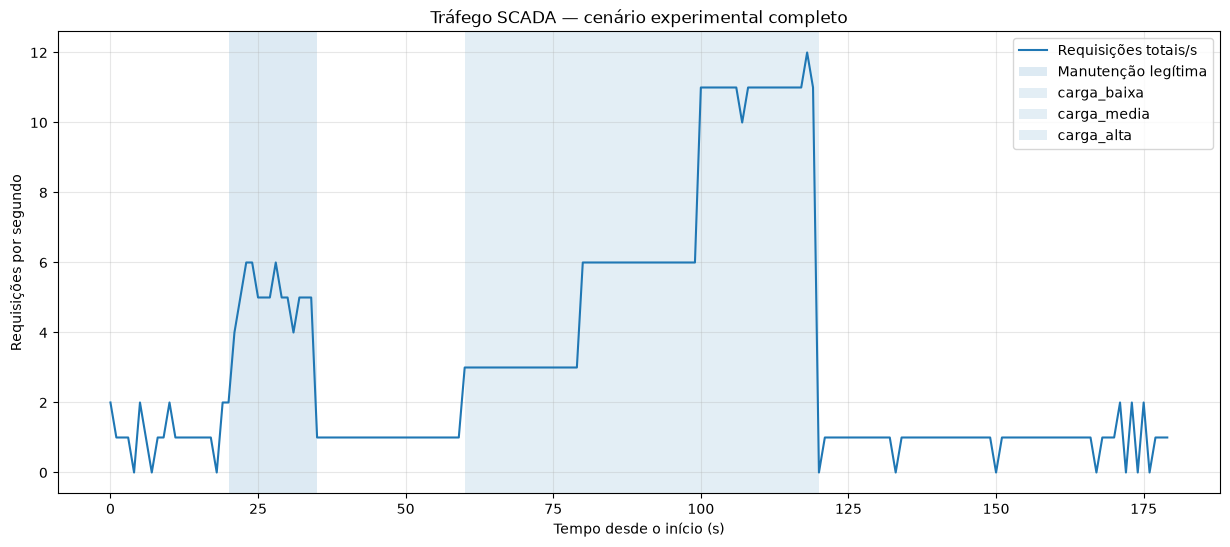

In [3]:
fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.plot(
    dados["segundo"],
    dados["taxa_requisicoes"],
    linewidth=1.5,
    label="Requisições totais/s"
)

# Manutenção legítima
for _, evento in atividades.iterrows():

    inicio = (
        evento["inicio"]
        - inicio_ensaio
    )

    fim = (
        evento["fim"]
        - inicio_ensaio
    )

    ax.axvspan(
        inicio,
        fim,
        alpha=0.15,
        label="Manutenção legítima"
    )

# Cargas
for _, evento in ataques.iterrows():

    inicio = (
        evento["inicio"]
        - inicio_ensaio
    )

    fim = (
        evento["fim"]
        - inicio_ensaio
    )

    ax.axvspan(
        inicio,
        fim,
        alpha=0.12,
        label=evento["tipo"]
    )

ax.set_title(
    "Tráfego SCADA — cenário experimental completo"
)

ax.set_xlabel(
    "Tempo desde o início (s)"
)

ax.set_ylabel(
    "Requisições por segundo"
)

ax.grid(alpha=0.3)
ax.legend()

plt.show()

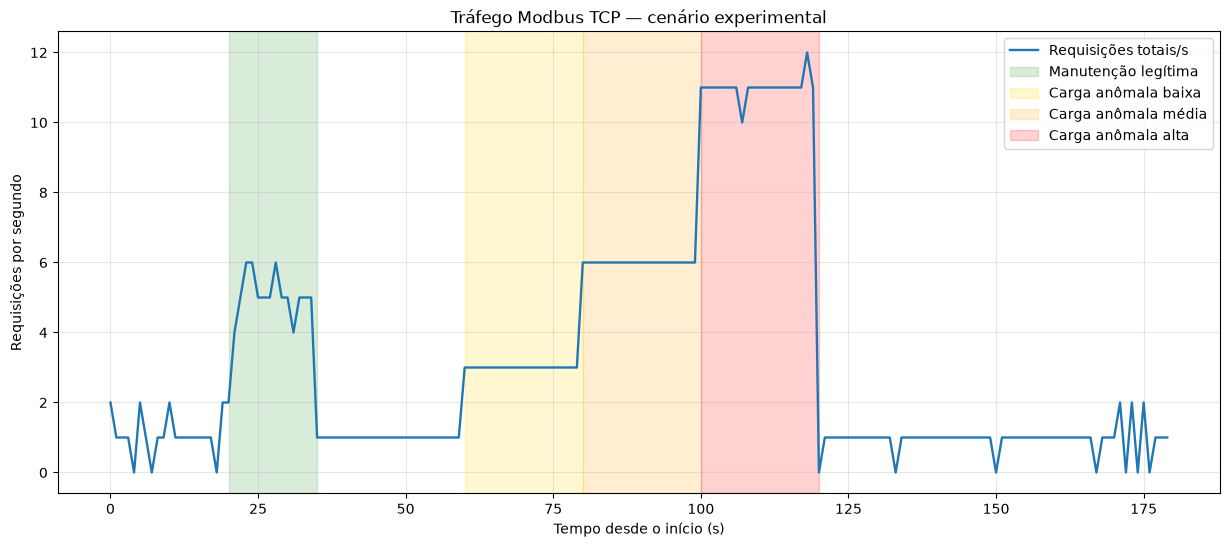

In [4]:
fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.plot(
    dados["segundo"],
    dados["taxa_requisicoes"],
    linewidth=1.7,
    label="Requisições totais/s"
)

# Manutenção legítima
for _, evento in atividades.iterrows():

    inicio = evento["inicio"] - inicio_ensaio
    fim = evento["fim"] - inicio_ensaio

    ax.axvspan(
        inicio,
        fim,
        color="green",
        alpha=0.15,
        label="Manutenção legítima"
    )

# Cargas anômalas
cores = {
    "carga_baixa": "gold",
    "carga_media": "orange",
    "carga_alta": "red"
}

nomes = {
    "carga_baixa": "Carga anômala baixa",
    "carga_media": "Carga anômala média",
    "carga_alta": "Carga anômala alta"
}

for _, evento in ataques.iterrows():

    inicio = evento["inicio"] - inicio_ensaio
    fim = evento["fim"] - inicio_ensaio

    tipo = evento["tipo"]

    ax.axvspan(
        inicio,
        fim,
        color=cores[tipo],
        alpha=0.18,
        label=nomes[tipo]
    )

ax.set_title(
    "Tráfego Modbus TCP — cenário experimental"
)

ax.set_xlabel(
    "Tempo desde o início (s)"
)

ax.set_ylabel(
    "Requisições por segundo"
)

ax.grid(alpha=0.3)
ax.legend()

plt.show()